In [1]:
from pathlib import Path
from typing import cast

import copy
import json
import time

# pytorch
import torch
from torch import nn
from torch_geometric.data import Data

from dataset import add_stratified_masks, load_facebook_data
from modules import GCNNetwork, GCNNetwork3Layer, GCNNetwork4Layer, GCNNetwork5Layer
from train import evaluate_gcn, train_gcn_epoch

# plotting
from matplotlib import pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns

## Multi-Layer GNN for Facebook Page Classification
### COMP3710 Working Prototype Project in the Era of Artificial Intelligence
#### Derek McKinney (dm-uq)
#### SN: 45506053

### GCN Experiments
<br>
References:

Facebook Page-Page dataset:
    https://github.com/gayanku/facebook_page-page_dataset

PyG FacebookPagePage:
    https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.datasets.FacebookPagePage.html

Config and Constants

In [2]:
# constants
SEED = 808

# data parameters
TRAIN_PCT = 60
VAL_PCT = 20
TEST_PCT = 20

# GCN model parameters
HIDDEN_CHANNELS = 64
DROPOUT = 0.5
DROPOUT_03 = 0.3
DROPOUT_07 = 0.7
DROPOUT_06 = 0.6

# hyper-parameters
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.0
EPOCHS = 4000
EPOCHS_2K = 2000

# plot styling
sns.set_theme(
    context="notebook",
    style="whitegrid",
)

# output paths
RESULTS_DIR = Path("results")
CHECKPOINTS_DIR = Path("checkpoints")
FIGURES_DIR = Path("images/gcn")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
# Device configuration
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Device: {device}")

if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

Device: cuda
NVIDIA GeForce GTX 950M


Load the Facebook Graph

In [4]:
# load the FacebookPagePage dataset
dataset = load_facebook_data()
data = dataset[0]  # get first graph object

# create reproducible stratified train/validation/test splits
add_stratified_masks(
    cast(Data, data),
    train_pct=TRAIN_PCT,
    val_pct=VAL_PCT,
    test_pct=TEST_PCT,
    seed=SEED,
)

# load data onto the device
data = data.to(device)

Instantiate the GCN network

In [5]:
gcn_model = GCNNetwork(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser

In [6]:
# loss criteria
criterion = nn.CrossEntropyLoss()

# optimiser
optimizer = torch.optim.Adam(
    gcn_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

Perform Initial GCN Experiment for comparison with MLP Baseline

In [ ]:
# perform training and validation of the Initial GCN

history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
}

best_val_loss = float("inf")
best_epoch = 0
best_state = None

print("> Training GCN")

start = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    train_loss = train_gcn_epoch(
        model=gcn_model,
        features=data.x,
        edge_index=data.edge_index,
        labels=data.y,
        train_mask=data.train_mask,
        criterion=criterion,
        optimizer=optimizer,
    )

    val_loss, val_accuracy = evaluate_gcn(
        model=gcn_model,
        features=data.x,
        edge_index=data.edge_index,
        labels=data.y,
        mask=data.val_mask,
        criterion=criterion,
    )

    # record training history for later visualisation
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    # retain the model with the lowest validation loss
    improved = val_loss < best_val_loss

    if improved:
        best_val_loss = val_loss
        best_epoch = epoch
        best_state = copy.deepcopy(
            gcn_model.state_dict()
        )

    marker = " *" if improved else ""

    print(
        f"Epoch [{epoch:3}/{EPOCHS}] "
        f"Train Loss: {train_loss:.5f} | "
        f"Val Loss: {val_loss:.5f} | "
        f"Val Acc: {val_accuracy:.2%}"
        f"{marker}"
    )

elapsed = time.perf_counter() - start

print(
    f"\nTraining took {elapsed:.2f} secs "
    f"or {elapsed / 60:.2f} mins in total."
)

print(
    f"Best validation loss: {best_val_loss:.5f} "
    f"at epoch {best_epoch}."
)

In [8]:
# save initial GCN experiment results

if best_state is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

gcn_results = {
    "model": "GCN",
    "experiment": "initial",
    "num_layers": 2,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": best_epoch,
    "best_val_loss": best_val_loss,
    "selected_val_accuracy": history[
        "val_accuracy"
    ][best_epoch - 1],
    "training_seconds": elapsed,
    "device": str(device),
    "history": history,
}

with (
    RESULTS_DIR / "gcn_initial.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn_results,
        file,
        indent=2,
    )

torch.save(
    best_state,
    CHECKPOINTS_DIR / "gcn_initial.pt",
)

Visualise the Train/Val metrics

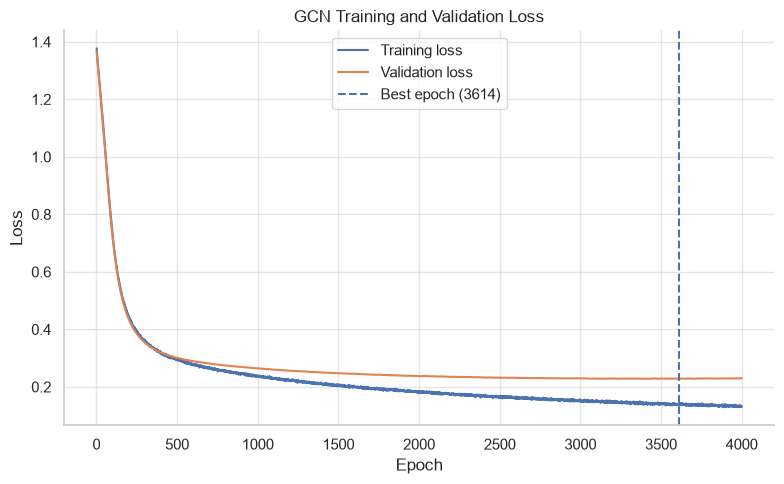

In [9]:
# plot the training and validation losses

gcn_epochs = range(
    1,
    len(history["train_loss"]) + 1
)

gcn_loss_fig, gcn_loss_ax = plt.subplots(
    figsize=(8, 5)
)

gcn_loss_ax.plot(
    gcn_epochs,
    history["train_loss"],
    label="Training loss",
)
gcn_loss_ax.plot(
    gcn_epochs,
    history["val_loss"],
    label="Validation loss",
)
gcn_loss_ax.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch ({best_epoch})",
)

gcn_loss_ax.set(
    xlabel="Epoch",
    ylabel="Loss",
    title="GCN Training and Validation Loss",
)
gcn_loss_ax.legend()

sns.despine(ax=gcn_loss_ax)
gcn_loss_fig.tight_layout()

plt.show()

In [10]:
# save the initial gcn validation loss plot
gcn_loss_fig.savefig(
    FIGURES_DIR / "gcn_training_validation_loss_initial_4000e.png",
    dpi=200,
    bbox_inches="tight"
)

Visualise the Validation Accuracy metrics

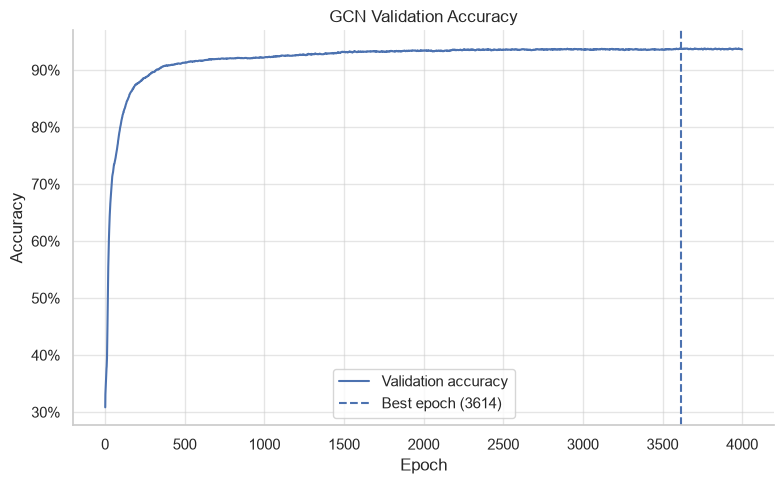

In [11]:
# plot GCN validation accuracy

gcn_accuracy_fig, gcn_accuracy_ax = plt.subplots(
    figsize=(8, 5)
)

gcn_accuracy_ax.plot(
    gcn_epochs,
    history["val_accuracy"],
    label="Validation accuracy",
)
gcn_accuracy_ax.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch ({best_epoch})",
)

gcn_accuracy_ax.set(
    xlabel="Epoch",
    ylabel="Accuracy",
    title="GCN Validation Accuracy",
)
gcn_accuracy_ax.yaxis.set_major_formatter(
    PercentFormatter(1.0)
)
gcn_accuracy_ax.legend()

sns.despine(ax=gcn_accuracy_ax)
gcn_accuracy_fig.tight_layout()

plt.show()

In [12]:
# save the initial gcn validation acc plot
gcn_accuracy_fig.savefig(
    FIGURES_DIR / "gcn_training_validation_acc_initial_4000e.png",
    dpi=200,
    bbox_inches="tight"
)

Evaluate the Initial GCN model performance

In [ ]:
# evaluate the initial GCN model on the held-out test set
# NOTE: final held-out GCN test evaluation - run only after model selection is complete
# NOTE: commented-out (temporarily) to prevent accidental run

# if best_state is None:
#     raise RuntimeError(
#         "No model state was recorded during training."
#     )
#
# gcn_model.load_state_dict(best_state)
#
# print(f"Restored model from epoch {best_epoch}.")
#
# test_loss, test_accuracy = evaluate_gcn(
#     model=gcn_model,
#     features=data.x,
#     edge_index=data.edge_index,
#     labels=data.y,
#     mask=data.test_mask,
#     criterion=criterion,
# )
#
# print(
#     f"Test Loss: {test_loss:.5f} | "
#     f"Test Accuracy: {test_accuracy:.2%}"
# )

Reset the Torch seed rng

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate a 3-Layer GCN Network

In [6]:
gcn3_model = GCNNetwork3Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 3-Layer GCN

In [7]:
# loss criteria
criterion = nn.CrossEntropyLoss()

# optimiser
gcn3_optimizer = torch.optim.Adam(
    gcn3_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

Perform 3-Layer GCN Experiment for comparison with Initial GCN Experiment

In [ ]:
# perform training and validation of the 3-layer GCN

gcn3_history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
}

gcn3_best_val_loss = float("inf")
gcn3_best_epoch = 0
gcn3_best_state = None

print("> Training 3-Layer GCN")

start = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    train_loss = train_gcn_epoch(
        model=gcn3_model,
        features=data.x,
        edge_index=data.edge_index,
        labels=data.y,
        train_mask=data.train_mask,
        criterion=criterion,
        optimizer=gcn3_optimizer,
    )

    val_loss, val_accuracy = evaluate_gcn(
        model=gcn3_model,
        features=data.x,
        edge_index=data.edge_index,
        labels=data.y,
        mask=data.val_mask,
        criterion=criterion,
    )

    # record training history for later visualisation
    gcn3_history["train_loss"].append(train_loss)
    gcn3_history["val_loss"].append(val_loss)
    gcn3_history["val_accuracy"].append(val_accuracy)

    # retain the model with the lowest validation loss
    improved = val_loss < gcn3_best_val_loss

    if improved:
        gcn3_best_val_loss = val_loss
        gcn3_best_epoch = epoch
        gcn3_best_state = copy.deepcopy(
            gcn3_model.state_dict()
        )

    marker = " *" if improved else ""

    print(
        f"Epoch [{epoch:3}/{EPOCHS}] "
        f"Train Loss: {train_loss:.5f} | "
        f"Val Loss: {val_loss:.5f} | "
        f"Val Acc: {val_accuracy:.2%}"
        f"{marker}"
    )

gcn3_elapsed = time.perf_counter() - start

print(
    f"\nTraining took {gcn3_elapsed:.2f} secs "
    f"or {gcn3_elapsed / 60:.2f} mins in total."
)

print(
    f"Best validation loss: {gcn3_best_val_loss:.5f} "
    f"at epoch {gcn3_best_epoch}."
)

In [9]:
# save 3-Layer GCN experiment results

if gcn3_best_state is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

gcn3_results = {
    "model": "GCN",
    "experiment": "depth",
    "num_layers": 3,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": gcn3_best_epoch,
    "best_val_loss": gcn3_best_val_loss,
    "selected_val_accuracy": gcn3_history[
        "val_accuracy"
    ][gcn3_best_epoch - 1],
    "training_seconds": gcn3_elapsed,
    "device": str(device),
    "history": gcn3_history,
}

with (
    RESULTS_DIR / "gcn_3layer.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn3_results,
        file,
        indent=2,
    )

torch.save(
    gcn3_best_state,
    CHECKPOINTS_DIR / "gcn_3layer.pt",
)

Visualise the Train/Val metrics for the 3-Layer GCN

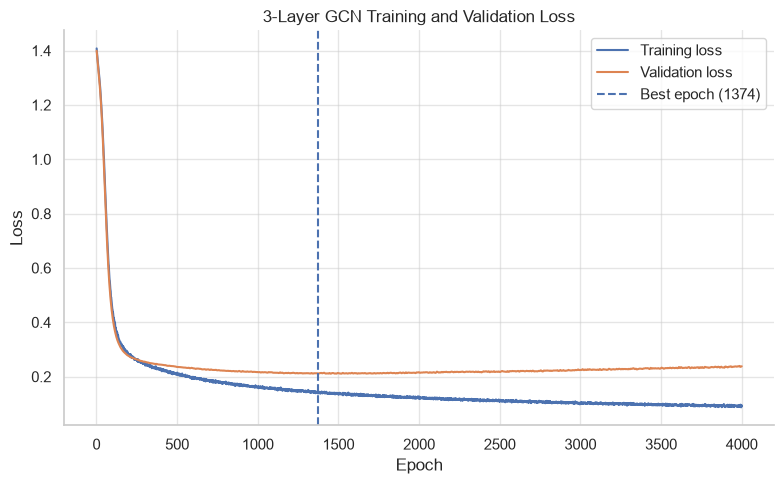

In [10]:
# plot the 3-Layer GCN training and validation losses

gcn3_epochs = range(
    1,
    len(gcn3_history["train_loss"]) + 1
)

gcn3_loss_fig, gcn3_loss_ax = plt.subplots(
    figsize=(8, 5)
)

gcn3_loss_ax.plot(
    gcn3_epochs,
    gcn3_history["train_loss"],
    label="Training loss",
)
gcn3_loss_ax.plot(
    gcn3_epochs,
    gcn3_history["val_loss"],
    label="Validation loss",
)
gcn3_loss_ax.axvline(
    gcn3_best_epoch,
    linestyle="--",
    label=f"Best epoch ({gcn3_best_epoch})",
)

gcn3_loss_ax.set(
    xlabel="Epoch",
    ylabel="Loss",
    title="3-Layer GCN Training and Validation Loss",
)
gcn3_loss_ax.legend()

sns.despine(ax=gcn3_loss_ax)
gcn3_loss_fig.tight_layout()

plt.show()

In [11]:
# save the 3-layer gcn validation loss plot
gcn3_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_3layer_training_validation_loss_4000e.png",
    dpi=200,
    bbox_inches="tight"
)

Visualise the Validation Accuracy metrics for the 3-Layer GCN

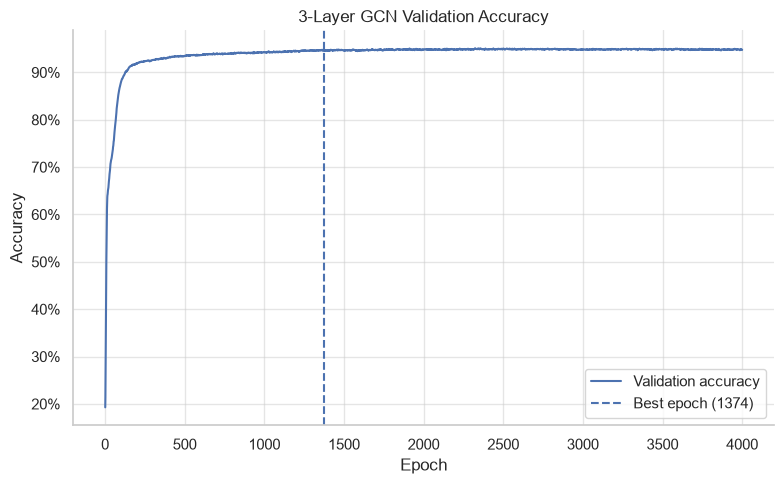

In [12]:
# plot 3-layer GCN validation accuracy

gcn3_accuracy_fig, gcn3_accuracy_ax = plt.subplots(
    figsize=(8, 5)
)

gcn3_accuracy_ax.plot(
    gcn3_epochs,
    gcn3_history["val_accuracy"],
    label="Validation accuracy",
)
gcn3_accuracy_ax.axvline(
    gcn3_best_epoch,
    linestyle="--",
    label=f"Best epoch ({gcn3_best_epoch})",
)

gcn3_accuracy_ax.set(
    xlabel="Epoch",
    ylabel="Accuracy",
    title="3-Layer GCN Validation Accuracy",
)
gcn3_accuracy_ax.yaxis.set_major_formatter(
    PercentFormatter(1.0)
)
gcn3_accuracy_ax.legend()

sns.despine(ax=gcn3_accuracy_ax)
gcn3_accuracy_fig.tight_layout()

plt.show()

In [13]:
# save the 3-layer gcn validation acc plot
gcn3_accuracy_fig.savefig(
    FIGURES_DIR / "gcn_3layer_training_validation_acc_4000e.png",
    dpi=200,
    bbox_inches="tight"
)

Reset for the next run

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate a 4-Layer GCN Network

In [6]:
gcn4_model = GCNNetwork4Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 4-Layer GCN

In [7]:
# loss criteria
criterion = nn.CrossEntropyLoss()

# optimiser
gcn4_optimizer = torch.optim.Adam(
    gcn4_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

Perform 4-Layer GCN Experiment for comparison with Initial GCN Experiment

In [ ]:
# perform training and validation of the 4-layer GCN

gcn4_history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
}

gcn4_best_val_loss = float("inf")
gcn4_best_epoch = 0
gcn4_best_state = None

print("> Training 4-Layer GCN")

start = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    train_loss = train_gcn_epoch(
        model=gcn4_model,
        features=data.x,
        edge_index=data.edge_index,
        labels=data.y,
        train_mask=data.train_mask,
        criterion=criterion,
        optimizer=gcn4_optimizer,
    )

    val_loss, val_accuracy = evaluate_gcn(
        model=gcn4_model,
        features=data.x,
        edge_index=data.edge_index,
        labels=data.y,
        mask=data.val_mask,
        criterion=criterion,
    )

    # record training history for later visualisation
    gcn4_history["train_loss"].append(train_loss)
    gcn4_history["val_loss"].append(val_loss)
    gcn4_history["val_accuracy"].append(val_accuracy)

    # retain the model with the lowest validation loss
    improved = val_loss < gcn4_best_val_loss

    if improved:
        gcn4_best_val_loss = val_loss
        gcn4_best_epoch = epoch
        gcn4_best_state = copy.deepcopy(
            gcn4_model.state_dict()
        )

    marker = " *" if improved else ""

    print(
        f"Epoch [{epoch:4}/{EPOCHS}] "
        f"Train Loss: {train_loss:.5f} | "
        f"Val Loss: {val_loss:.5f} | "
        f"Val Acc: {val_accuracy:.2%}"
        f"{marker}"
    )

gcn4_elapsed = time.perf_counter() - start

print(
    f"\nTraining took {gcn4_elapsed:.2f} secs "
    f"or {gcn4_elapsed / 60:.2f} mins in total."
)

print(
    f"Best validation loss: {gcn4_best_val_loss:.5f} "
    f"at epoch {gcn4_best_epoch}."
)

In [9]:
# save 4-Layer GCN experiment results

if gcn4_best_state is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

gcn4_results = {
    "model": "GCN",
    "experiment": "depth",
    "num_layers": 4,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": gcn4_best_epoch,
    "best_val_loss": gcn4_best_val_loss,
    "selected_val_accuracy": gcn4_history[
        "val_accuracy"
    ][gcn4_best_epoch - 1],
    "training_seconds": gcn4_elapsed,
    "device": str(device),
    "history": gcn4_history,
}

with (
    RESULTS_DIR / "gcn_4layer.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn4_results,
        file,
        indent=2,
    )

torch.save(
    gcn4_best_state,
    CHECKPOINTS_DIR / "gcn_4layer.pt",
)

Visualise the Train/Val metrics for the 4-Layer GCN

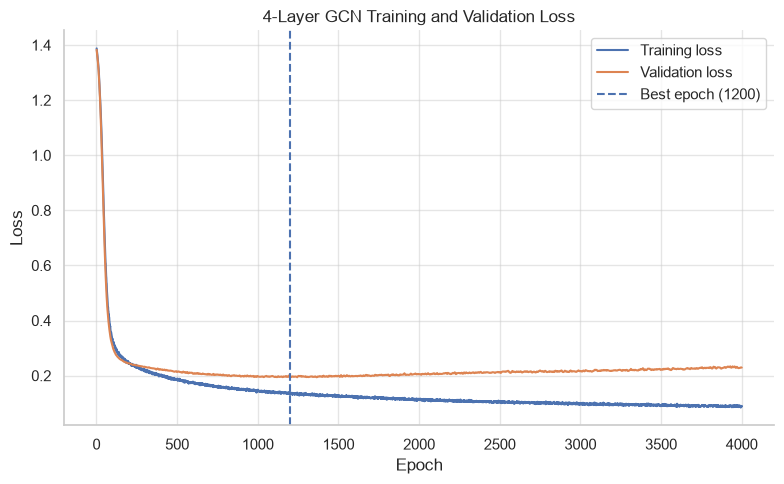

In [10]:
# plot the 4-Layer GCN training and validation losses

gcn4_epochs = range(
    1,
    len(gcn4_history["train_loss"]) + 1
)

gcn4_loss_fig, gcn4_loss_ax = plt.subplots(
    figsize=(8, 5)
)

gcn4_loss_ax.plot(
    gcn4_epochs,
    gcn4_history["train_loss"],
    label="Training loss",
)
gcn4_loss_ax.plot(
    gcn4_epochs,
    gcn4_history["val_loss"],
    label="Validation loss",
)
gcn4_loss_ax.axvline(
    gcn4_best_epoch,
    linestyle="--",
    label=f"Best epoch ({gcn4_best_epoch})",
)

gcn4_loss_ax.set(
    xlabel="Epoch",
    ylabel="Loss",
    title="4-Layer GCN Training and Validation Loss",
)
gcn4_loss_ax.legend()

sns.despine(ax=gcn4_loss_ax)
gcn4_loss_fig.tight_layout()

plt.show()

In [11]:
# save the 4-layer gcn validation loss plot
gcn4_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_4layer_training_validation_loss_4000e.png",
    dpi=200,
    bbox_inches="tight"
)

Visualise the Validation Accuracy metrics for the 4-Layer GCN

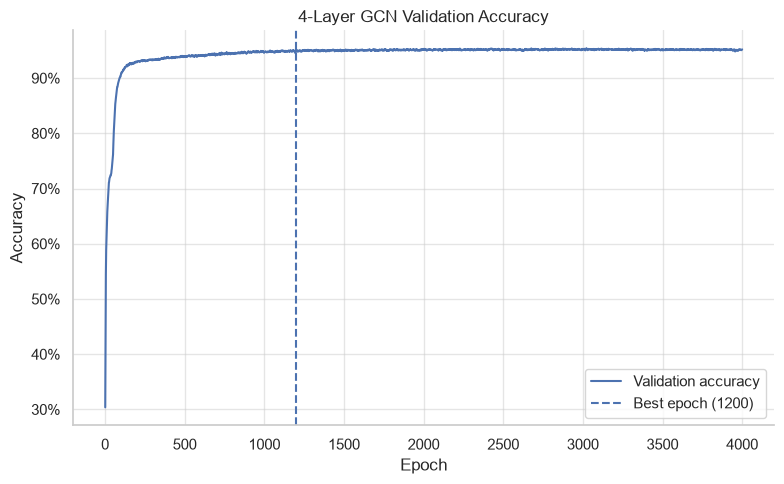

In [12]:
# plot 4-layer GCN validation accuracy

gcn4_accuracy_fig, gcn4_accuracy_ax = plt.subplots(
    figsize=(8, 5)
)

gcn4_accuracy_ax.plot(
    gcn4_epochs,
    gcn4_history["val_accuracy"],
    label="Validation accuracy",
)
gcn4_accuracy_ax.axvline(
    gcn4_best_epoch,
    linestyle="--",
    label=f"Best epoch ({gcn4_best_epoch})",
)

gcn4_accuracy_ax.set(
    xlabel="Epoch",
    ylabel="Accuracy",
    title="4-Layer GCN Validation Accuracy",
)
gcn4_accuracy_ax.yaxis.set_major_formatter(
    PercentFormatter(1.0)
)
gcn4_accuracy_ax.legend()

sns.despine(ax=gcn4_accuracy_ax)
gcn4_accuracy_fig.tight_layout()

plt.show()

In [13]:
# save the 4-layer gcn validation acc plot
gcn4_accuracy_fig.savefig(
    FIGURES_DIR / "gcn_4layer_training_validation_acc_4000e.png",
    dpi=200,
    bbox_inches="tight"
)

Reset for the next run

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate a 5-Layer GCN Network

In [6]:
gcn5_model = GCNNetwork5Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT,
).to(device)

Define the Loss function and Optimiser for the 5-Layer GCN

In [7]:
# loss criteria
criterion = nn.CrossEntropyLoss()

# optimiser
gcn5_optimizer = torch.optim.Adam(
    gcn5_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

Perform 5-Layer GCN Experiment for comparison with Initial GCN Experiment

In [ ]:
# perform training and validation of the 5-layer GCN

gcn5_history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
}

gcn5_best_val_loss = float("inf")
gcn5_best_epoch = 0
gcn5_best_state = None

print("> Training 5-Layer GCN")

start = time.perf_counter()

for epoch in range(1, EPOCHS_2K + 1):
    train_loss = train_gcn_epoch(
        model=gcn5_model,
        features=data.x,
        edge_index=data.edge_index,
        labels=data.y,
        train_mask=data.train_mask,
        criterion=criterion,
        optimizer=gcn5_optimizer,
    )

    val_loss, val_accuracy = evaluate_gcn(
        model=gcn5_model,
        features=data.x,
        edge_index=data.edge_index,
        labels=data.y,
        mask=data.val_mask,
        criterion=criterion,
    )

    # record training history for later visualisation
    gcn5_history["train_loss"].append(train_loss)
    gcn5_history["val_loss"].append(val_loss)
    gcn5_history["val_accuracy"].append(val_accuracy)

    # retain the model with the lowest validation loss
    improved = val_loss < gcn5_best_val_loss

    if improved:
        gcn5_best_val_loss = val_loss
        gcn5_best_epoch = epoch
        gcn5_best_state = copy.deepcopy(
            gcn5_model.state_dict()
        )

    marker = " *" if improved else ""

    print(
        f"Epoch [{epoch:5}/{EPOCHS_2K}] "
        f"Train Loss: {train_loss:.5f} | "
        f"Val Loss: {val_loss:.5f} | "
        f"Val Acc: {val_accuracy:.2%}"
        f"{marker}"
    )

gcn5_elapsed = time.perf_counter() - start

print(
    f"\nTraining took {gcn5_elapsed:.2f} secs "
    f"or {gcn5_elapsed / 60:.2f} mins in total."
)

print(
    f"Best validation loss: {gcn5_best_val_loss:.5f} "
    f"at epoch {gcn5_best_epoch}."
)

In [9]:
# save 5-Layer GCN experiment results

if gcn5_best_state is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

gcn5_results = {
    "model": "GCN",
    "experiment": "depth",
    "num_layers": 5,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": gcn5_best_epoch,
    "best_val_loss": gcn5_best_val_loss,
    "selected_val_accuracy": gcn5_history[
        "val_accuracy"
    ][gcn5_best_epoch - 1],
    "training_seconds": gcn5_elapsed,
    "device": str(device),
    "history": gcn5_history,
}

with (
    RESULTS_DIR / "gcn_5layer.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn5_results,
        file,
        indent=2,
    )

torch.save(
    gcn5_best_state,
    CHECKPOINTS_DIR / "gcn_5layer.pt",
)

Visualise the Train/Val metrics for the 5-Layer GCN

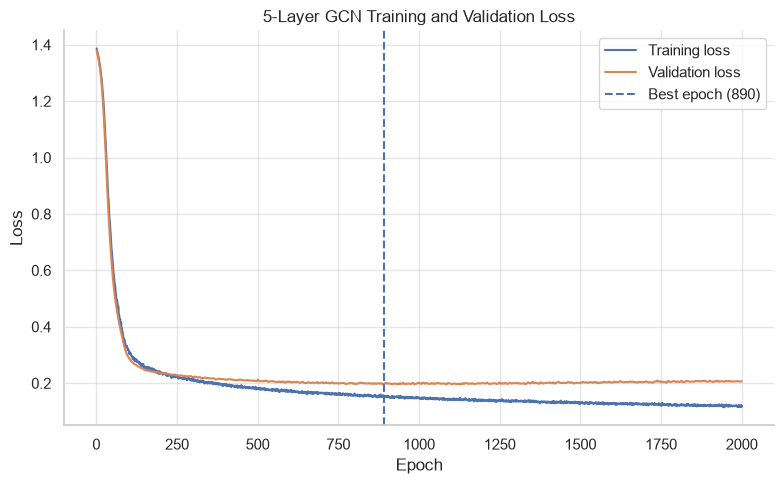

In [10]:
# plot the 5-Layer GCN training and validation losses

gcn5_epochs = range(
    1,
    len(gcn5_history["train_loss"]) + 1
)

gcn5_loss_fig, gcn5_loss_ax = plt.subplots(
    figsize=(8, 5)
)

gcn5_loss_ax.plot(
    gcn5_epochs,
    gcn5_history["train_loss"],
    label="Training loss",
)
gcn5_loss_ax.plot(
    gcn5_epochs,
    gcn5_history["val_loss"],
    label="Validation loss",
)
gcn5_loss_ax.axvline(
    gcn5_best_epoch,
    linestyle="--",
    label=f"Best epoch ({gcn5_best_epoch})",
)

gcn5_loss_ax.set(
    xlabel="Epoch",
    ylabel="Loss",
    title="5-Layer GCN Training and Validation Loss",
)
gcn5_loss_ax.legend()

sns.despine(ax=gcn5_loss_ax)
gcn5_loss_fig.tight_layout()

plt.show()

In [11]:
# save the 5-layer gcn validation loss plot
gcn5_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_5layer_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight"
)

Visualise the Validation Accuracy metrics for the 5-Layer GCN

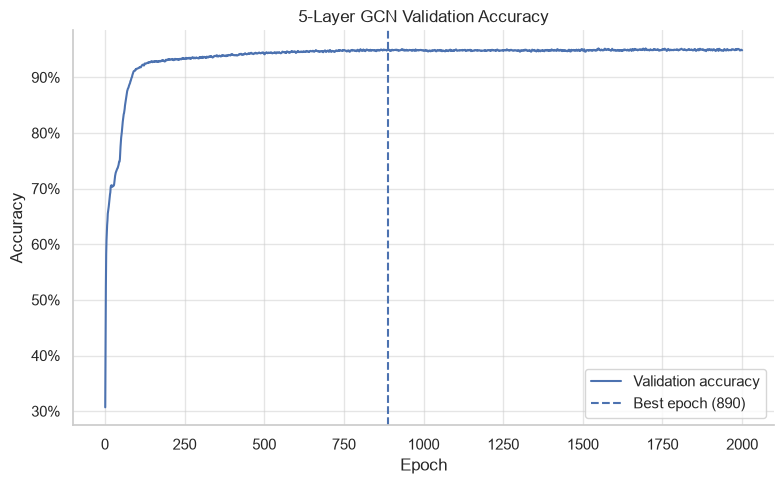

In [12]:
# plot 5-layer GCN validation accuracy

gcn5_accuracy_fig, gcn5_accuracy_ax = plt.subplots(
    figsize=(8, 5)
)

gcn5_accuracy_ax.plot(
    gcn5_epochs,
    gcn5_history["val_accuracy"],
    label="Validation accuracy",
)
gcn5_accuracy_ax.axvline(
    gcn5_best_epoch,
    linestyle="--",
    label=f"Best epoch ({gcn5_best_epoch})",
)

gcn5_accuracy_ax.set(
    xlabel="Epoch",
    ylabel="Accuracy",
    title="5-Layer GCN Validation Accuracy",
)
gcn5_accuracy_ax.yaxis.set_major_formatter(
    PercentFormatter(1.0)
)
gcn5_accuracy_ax.legend()

sns.despine(ax=gcn5_accuracy_ax)
gcn5_accuracy_fig.tight_layout()

plt.show()

In [13]:
# save the 5-layer gcn validation acc plot
gcn5_accuracy_fig.savefig(
    FIGURES_DIR / "gcn_5layer_training_validation_acc_2000e.png",
    dpi=200,
    bbox_inches="tight"
)

Reset for the next run

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate a 4-Layer GCN Network with dropout=0.3

In [6]:
gcn4_drop_03_model = GCNNetwork4Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT_03,
).to(device)

Define the Loss function and Optimiser for the 4-Layer GCN (dropout=0.3)

In [7]:
# loss criteria
criterion = nn.CrossEntropyLoss()

# optimiser
gcn4_drop_03_optimizer = torch.optim.Adam(
    gcn4_drop_03_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

Perform 4-Layer GCN (dropout=0.3) Experiment for comparison with Initial GCN Experiment

In [ ]:
# perform training and validation of the 4-layer GCN (dropout=0.3)

gcn4_drop_03_history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
}

gcn4_drop_03_best_val_loss = float("inf")
gcn4_drop_03_best_epoch = 0
gcn4_drop_03_best_state = None

print("> Training 4-Layer GCN (dropout=0.3)")

start = time.perf_counter()

for epoch in range(1, EPOCHS_2K + 1):
    train_loss = train_gcn_epoch(
        model=gcn4_drop_03_model,
        features=data.x,
        edge_index=data.edge_index,
        labels=data.y,
        train_mask=data.train_mask,
        criterion=criterion,
        optimizer=gcn4_drop_03_optimizer,
    )

    val_loss, val_accuracy = evaluate_gcn(
        model=gcn4_drop_03_model,
        features=data.x,
        edge_index=data.edge_index,
        labels=data.y,
        mask=data.val_mask,
        criterion=criterion,
    )

    # record training history for later visualisation
    gcn4_drop_03_history["train_loss"].append(train_loss)
    gcn4_drop_03_history["val_loss"].append(val_loss)
    gcn4_drop_03_history["val_accuracy"].append(val_accuracy)

    # retain the model with the lowest validation loss
    improved = val_loss < gcn4_drop_03_best_val_loss

    if improved:
        gcn4_drop_03_best_val_loss = val_loss
        gcn4_drop_03_best_epoch = epoch
        gcn4_drop_03_best_state = copy.deepcopy(
            gcn4_drop_03_model.state_dict()
        )

    marker = " *" if improved else ""

    print(
        f"Epoch [{epoch:4}/{EPOCHS_2K}] "
        f"Train Loss: {train_loss:.5f} | "
        f"Val Loss: {val_loss:.5f} | "
        f"Val Acc: {val_accuracy:.2%}"
        f"{marker}"
    )

gcn4_drop_03_elapsed = time.perf_counter() - start

print(
    f"\nTraining took {gcn4_drop_03_elapsed:.2f} secs "
    f"or {gcn4_drop_03_elapsed / 60:.2f} mins in total."
)

print(
    f"Best validation loss: {gcn4_drop_03_best_val_loss:.5f} "
    f"at epoch {gcn4_drop_03_best_epoch}."
)

In [10]:
# save 4-Layer GCN (dropout=0.3) experiment results

if gcn4_drop_03_best_state is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

gcn4_drop_03_results = {
    "model": "GCN",
    "experiment": "dropout",
    "num_layers": 4,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT_03,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": gcn4_drop_03_best_epoch,
    "best_val_loss": gcn4_drop_03_best_val_loss,
    "selected_val_accuracy": gcn4_drop_03_history[
        "val_accuracy"
    ][gcn4_drop_03_best_epoch - 1],
    "training_seconds": gcn4_drop_03_elapsed,
    "device": str(device),
    "history": gcn4_drop_03_history,
}

with (
    RESULTS_DIR / "gcn_4layer_dropout03.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn4_drop_03_results,
        file,
        indent=2,
    )

torch.save(
    gcn4_drop_03_best_state,
    CHECKPOINTS_DIR / "gcn_4layer_dropout03.pt",
)

Visualise the Train/Val metrics for the 4-Layer GCN with dropout=0.3

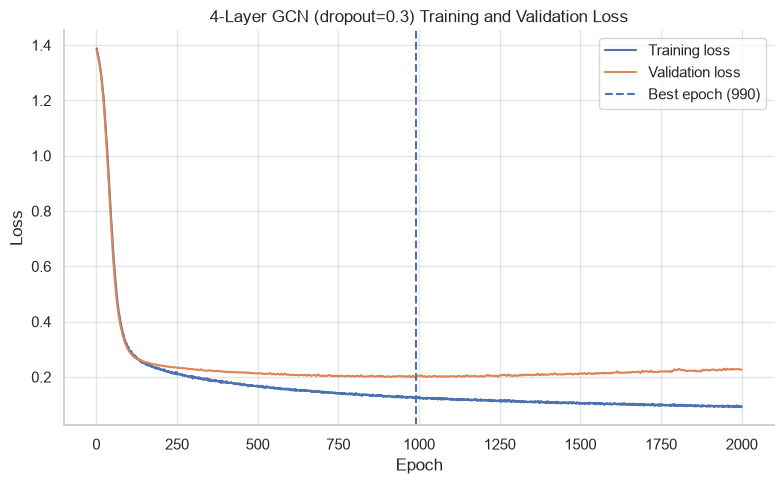

In [11]:
# plot the 4-Layer GCN (dropout=0.3) training and validation losses

gcn4_drop_03_epochs = range(
    1,
    len(gcn4_drop_03_history["train_loss"]) + 1
)

gcn4_drop_03_loss_fig, gcn4_drop_03_loss_ax = plt.subplots(
    figsize=(8, 5)
)

gcn4_drop_03_loss_ax.plot(
    gcn4_drop_03_epochs,
    gcn4_drop_03_history["train_loss"],
    label="Training loss",
)
gcn4_drop_03_loss_ax.plot(
    gcn4_drop_03_epochs,
    gcn4_drop_03_history["val_loss"],
    label="Validation loss",
)
gcn4_drop_03_loss_ax.axvline(
    gcn4_drop_03_best_epoch,
    linestyle="--",
    label=f"Best epoch ({gcn4_drop_03_best_epoch})",
)

gcn4_drop_03_loss_ax.set(
    xlabel="Epoch",
    ylabel="Loss",
    title="4-Layer GCN (dropout=0.3) Training and Validation Loss",
)
gcn4_drop_03_loss_ax.legend()

sns.despine(ax=gcn4_drop_03_loss_ax)
gcn4_drop_03_loss_fig.tight_layout()

plt.show()

In [12]:
# save the 4-layer gcn (dropout=0.3) validation loss plot
gcn4_drop_03_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_4layer_dropout03_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight"
)

Visualise the Validation Accuracy metrics for the 4-Layer GCN with dropout=0.3

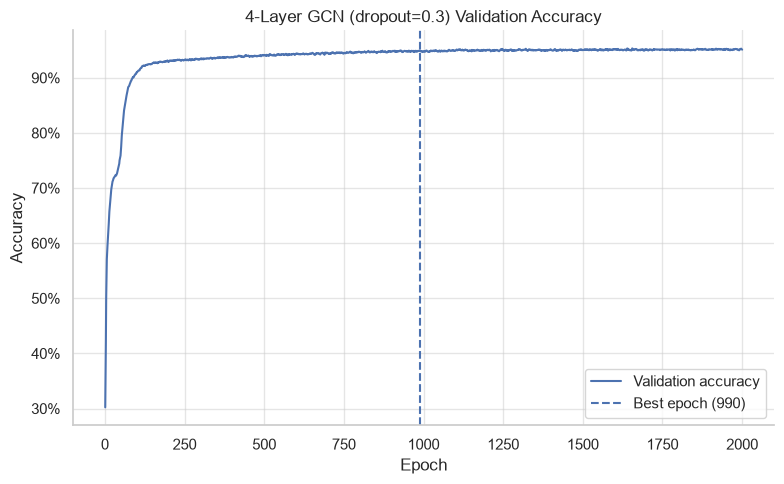

In [13]:
# plot 4-layer GCN (dropout=0.3) validation accuracy

gcn4_drop_03_accuracy_fig, gcn4_drop_03_accuracy_ax = plt.subplots(
    figsize=(8, 5)
)

gcn4_drop_03_accuracy_ax.plot(
    gcn4_drop_03_epochs,
    gcn4_drop_03_history["val_accuracy"],
    label="Validation accuracy",
)
gcn4_drop_03_accuracy_ax.axvline(
    gcn4_drop_03_best_epoch,
    linestyle="--",
    label=f"Best epoch ({gcn4_drop_03_best_epoch})",
)

gcn4_drop_03_accuracy_ax.set(
    xlabel="Epoch",
    ylabel="Accuracy",
    title="4-Layer GCN (dropout=0.3) Validation Accuracy",
)
gcn4_drop_03_accuracy_ax.yaxis.set_major_formatter(
    PercentFormatter(1.0)
)
gcn4_drop_03_accuracy_ax.legend()

sns.despine(ax=gcn4_drop_03_accuracy_ax)
gcn4_drop_03_accuracy_fig.tight_layout()

plt.show()

In [14]:
# save the 4-layer gcn (dropout=0.3) validation acc plot
gcn4_drop_03_accuracy_fig.savefig(
    FIGURES_DIR / "gcn_4layer_dropout03_training_validation_acc_2000e.png",
    dpi=200,
    bbox_inches="tight"
)

Reset for the next run

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate a 4-Layer GCN Network with dropout=0.7

In [6]:
gcn4_drop_07_model = GCNNetwork4Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT_07,
).to(device)

Define the Loss function and Optimiser for the 4-Layer GCN (dropout=0.7)

In [7]:
# loss criteria
criterion = nn.CrossEntropyLoss()

# optimiser
gcn4_drop_07_optimizer = torch.optim.Adam(
    gcn4_drop_07_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

Perform 4-Layer GCN (dropout=0.7) Experiment for comparison with Initial GCN Experiment

In [ ]:
# perform training and validation of the 4-layer GCN (dropout=0.7)

gcn4_drop_07_history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
}

gcn4_drop_07_best_val_loss = float("inf")
gcn4_drop_07_best_epoch = 0
gcn4_drop_07_best_state = None

print("> Training 4-Layer GCN (dropout=0.7)")

start = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    train_loss = train_gcn_epoch(
        model=gcn4_drop_07_model,
        features=data.x,
        edge_index=data.edge_index,
        labels=data.y,
        train_mask=data.train_mask,
        criterion=criterion,
        optimizer=gcn4_drop_07_optimizer,
    )

    val_loss, val_accuracy = evaluate_gcn(
        model=gcn4_drop_07_model,
        features=data.x,
        edge_index=data.edge_index,
        labels=data.y,
        mask=data.val_mask,
        criterion=criterion,
    )

    # record training history for later visualisation
    gcn4_drop_07_history["train_loss"].append(train_loss)
    gcn4_drop_07_history["val_loss"].append(val_loss)
    gcn4_drop_07_history["val_accuracy"].append(val_accuracy)

    # retain the model with the lowest validation loss
    improved = val_loss < gcn4_drop_07_best_val_loss

    if improved:
        gcn4_drop_07_best_val_loss = val_loss
        gcn4_drop_07_best_epoch = epoch
        gcn4_drop_07_best_state = copy.deepcopy(
            gcn4_drop_07_model.state_dict()
        )

    marker = " *" if improved else ""

    print(
        f"Epoch [{epoch:4}/{EPOCHS}] "
        f"Train Loss: {train_loss:.5f} | "
        f"Val Loss: {val_loss:.5f} | "
        f"Val Acc: {val_accuracy:.2%}"
        f"{marker}"
    )

gcn4_drop_07_elapsed = time.perf_counter() - start

print(
    f"\nTraining took {gcn4_drop_07_elapsed:.2f} secs "
    f"or {gcn4_drop_07_elapsed / 60:.2f} mins in total."
)

print(
    f"Best validation loss: {gcn4_drop_07_best_val_loss:.5f} "
    f"at epoch {gcn4_drop_07_best_epoch}."
)

In [9]:
# save 4-Layer GCN (dropout=0.7) experiment results

if gcn4_drop_07_best_state is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

gcn4_drop_07_results = {
    "model": "GCN",
    "experiment": "dropout",
    "num_layers": 4,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT_07,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": gcn4_drop_07_best_epoch,
    "best_val_loss": gcn4_drop_07_best_val_loss,
    "selected_val_accuracy": gcn4_drop_07_history[
        "val_accuracy"
    ][gcn4_drop_07_best_epoch - 1],
    "training_seconds": gcn4_drop_07_elapsed,
    "device": str(device),
    "history": gcn4_drop_07_history,
}

with (
    RESULTS_DIR / "gcn_4layer_dropout07.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn4_drop_07_results,
        file,
        indent=2,
    )

torch.save(
    gcn4_drop_07_best_state,
    CHECKPOINTS_DIR / "gcn_4layer_dropout07.pt",
)

Visualise the Train/Val metrics for the 4-Layer GCN with dropout=0.7

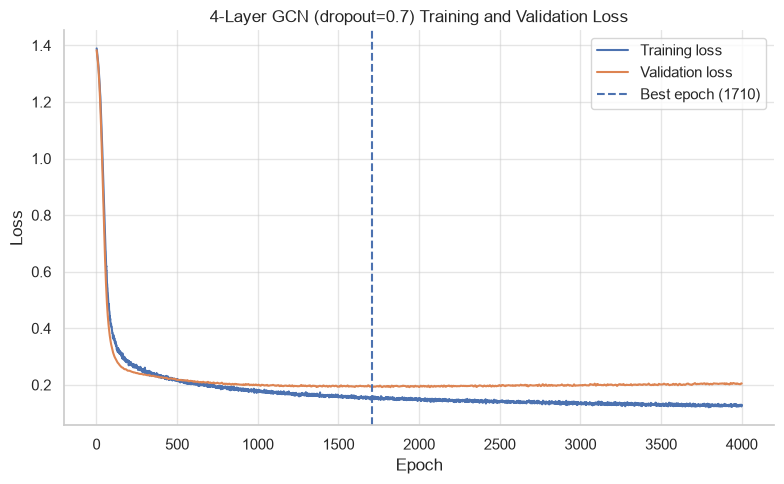

In [10]:
# plot the 4-Layer GCN (dropout=0.7) training and validation losses

gcn4_drop_07_epochs = range(
    1,
    len(gcn4_drop_07_history["train_loss"]) + 1
)

gcn4_drop_07_loss_fig, gcn4_drop_07_loss_ax = plt.subplots(
    figsize=(8, 5)
)

gcn4_drop_07_loss_ax.plot(
    gcn4_drop_07_epochs,
    gcn4_drop_07_history["train_loss"],
    label="Training loss",
)
gcn4_drop_07_loss_ax.plot(
    gcn4_drop_07_epochs,
    gcn4_drop_07_history["val_loss"],
    label="Validation loss",
)
gcn4_drop_07_loss_ax.axvline(
    gcn4_drop_07_best_epoch,
    linestyle="--",
    label=f"Best epoch ({gcn4_drop_07_best_epoch})",
)

gcn4_drop_07_loss_ax.set(
    xlabel="Epoch",
    ylabel="Loss",
    title="4-Layer GCN (dropout=0.7) Training and Validation Loss",
)
gcn4_drop_07_loss_ax.legend()

sns.despine(ax=gcn4_drop_07_loss_ax)
gcn4_drop_07_loss_fig.tight_layout()

plt.show()

In [11]:
# save the 4-layer gcn (dropout=0.7) validation loss plot
gcn4_drop_07_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_4layer_dropout07_training_validation_loss_4000e.png",
    dpi=200,
    bbox_inches="tight"
)

Visualise the Validation Accuracy metrics for the 4-Layer GCN with dropout=0.7

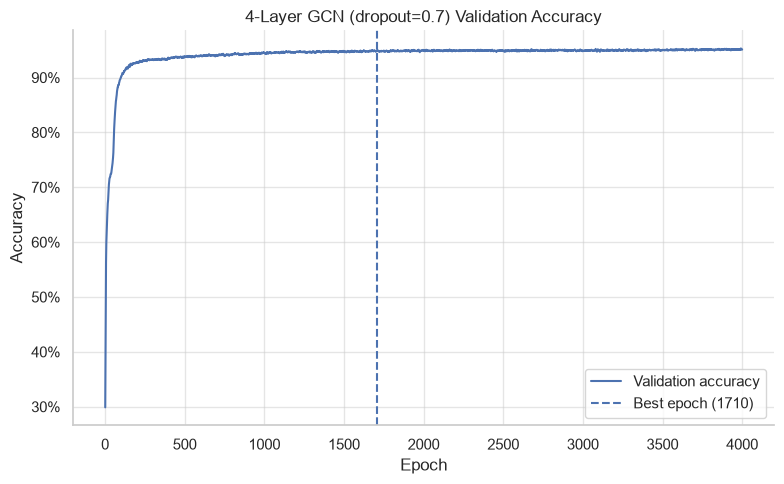

In [12]:
# plot 4-layer GCN (dropout=0.7) validation accuracy

gcn4_drop_07_accuracy_fig, gcn4_drop_07_accuracy_ax = plt.subplots(
    figsize=(8, 5)
)

gcn4_drop_07_accuracy_ax.plot(
    gcn4_drop_07_epochs,
    gcn4_drop_07_history["val_accuracy"],
    label="Validation accuracy",
)
gcn4_drop_07_accuracy_ax.axvline(
    gcn4_drop_07_best_epoch,
    linestyle="--",
    label=f"Best epoch ({gcn4_drop_07_best_epoch})",
)

gcn4_drop_07_accuracy_ax.set(
    xlabel="Epoch",
    ylabel="Accuracy",
    title="4-Layer GCN (dropout=0.7) Validation Accuracy",
)
gcn4_drop_07_accuracy_ax.yaxis.set_major_formatter(
    PercentFormatter(1.0)
)
gcn4_drop_07_accuracy_ax.legend()

sns.despine(ax=gcn4_drop_07_accuracy_ax)
gcn4_drop_07_accuracy_fig.tight_layout()

plt.show()

In [13]:
# save the 4-layer gcn (dropout=0.7) validation acc plot
gcn4_drop_07_accuracy_fig.savefig(
    FIGURES_DIR / "gcn_4layer_dropout07_training_validation_acc_4000e.png",
    dpi=200,
    bbox_inches="tight"
)

Reset for the next run

In [5]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Instantiate a 4-Layer GCN Network with dropout=0.6

In [6]:
gcn4_drop_06_model = GCNNetwork4Layer(
    in_channels=data.num_node_features,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=dataset.num_classes,
    dropout=DROPOUT_06,
).to(device)

Define the Loss function and Optimiser for the 4-Layer GCN (dropout=0.6)

In [7]:
# loss criteria
criterion = nn.CrossEntropyLoss()

# optimiser
gcn4_drop_06_optimizer = torch.optim.Adam(
    gcn4_drop_06_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

Perform 4-Layer GCN (dropout=0.6) Experiment for comparison with Initial GCN Experiment

In [ ]:
# perform training and validation of the 4-layer GCN (dropout=0.6)

gcn4_drop_06_history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
}

gcn4_drop_06_best_val_loss = float("inf")
gcn4_drop_06_best_epoch = 0
gcn4_drop_06_best_state = None

print("> Training 4-Layer GCN (dropout=0.6)")

start = time.perf_counter()

for epoch in range(1, EPOCHS_2K + 1):
    train_loss = train_gcn_epoch(
        model=gcn4_drop_06_model,
        features=data.x,
        edge_index=data.edge_index,
        labels=data.y,
        train_mask=data.train_mask,
        criterion=criterion,
        optimizer=gcn4_drop_06_optimizer,
    )

    val_loss, val_accuracy = evaluate_gcn(
        model=gcn4_drop_06_model,
        features=data.x,
        edge_index=data.edge_index,
        labels=data.y,
        mask=data.val_mask,
        criterion=criterion,
    )

    # record training history for later visualisation
    gcn4_drop_06_history["train_loss"].append(train_loss)
    gcn4_drop_06_history["val_loss"].append(val_loss)
    gcn4_drop_06_history["val_accuracy"].append(val_accuracy)

    # retain the model with the lowest validation loss
    improved = val_loss < gcn4_drop_06_best_val_loss

    if improved:
        gcn4_drop_06_best_val_loss = val_loss
        gcn4_drop_06_best_epoch = epoch
        gcn4_drop_06_best_state = copy.deepcopy(
            gcn4_drop_06_model.state_dict()
        )

    marker = " *" if improved else ""

    print(
        f"Epoch [{epoch:4}/{EPOCHS_2K}] "
        f"Train Loss: {train_loss:.5f} | "
        f"Val Loss: {val_loss:.5f} | "
        f"Val Acc: {val_accuracy:.2%}"
        f"{marker}"
    )

gcn4_drop_06_elapsed = time.perf_counter() - start

print(
    f"\nTraining took {gcn4_drop_06_elapsed:.2f} secs "
    f"or {gcn4_drop_06_elapsed / 60:.2f} mins in total."
)

print(
    f"Best validation loss: {gcn4_drop_06_best_val_loss:.5f} "
    f"at epoch {gcn4_drop_06_best_epoch}."
)

In [9]:
# save 4-Layer GCN (dropout=0.6) experiment results

if gcn4_drop_06_best_state is None:
    raise RuntimeError(
        "No model state was recorded during training."
    )

gcn4_drop_06_results = {
    "model": "GCN",
    "experiment": "dropout",
    "num_layers": 4,
    "seed": SEED,
    "train_pct": TRAIN_PCT,
    "val_pct": VAL_PCT,
    "test_pct": TEST_PCT,
    "epochs": EPOCHS_2K,
    "hidden_channels": HIDDEN_CHANNELS,
    "dropout": DROPOUT_06,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": gcn4_drop_06_best_epoch,
    "best_val_loss": gcn4_drop_06_best_val_loss,
    "selected_val_accuracy": gcn4_drop_06_history[
        "val_accuracy"
    ][gcn4_drop_06_best_epoch - 1],
    "training_seconds": gcn4_drop_06_elapsed,
    "device": str(device),
    "history": gcn4_drop_06_history,
}

with (
    RESULTS_DIR / "gcn_4layer_dropout06.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        gcn4_drop_06_results,
        file,
        indent=2,
    )

torch.save(
    gcn4_drop_06_best_state,
    CHECKPOINTS_DIR / "gcn_4layer_dropout06.pt",
)

Visualise the Train/Val metrics for the 4-Layer GCN with dropout=0.6

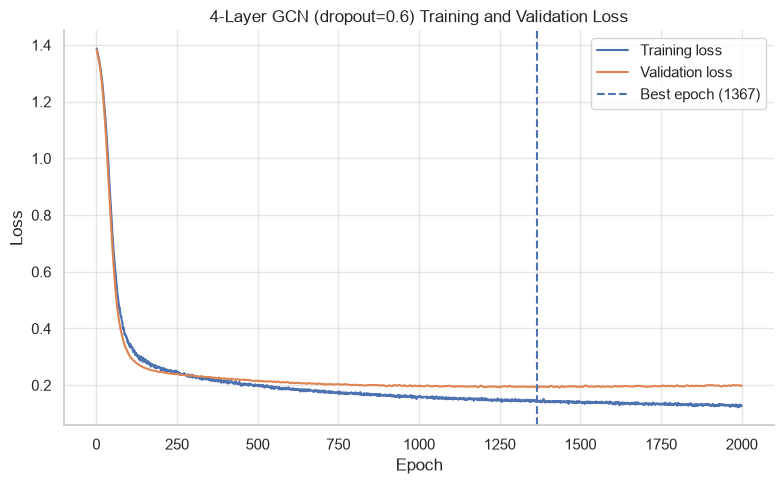

In [10]:
# plot the 4-Layer GCN (dropout=0.6) training and validation losses

gcn4_drop_06_epochs = range(
    1,
    len(gcn4_drop_06_history["train_loss"]) + 1
)

gcn4_drop_06_loss_fig, gcn4_drop_06_loss_ax = plt.subplots(
    figsize=(8, 5)
)

gcn4_drop_06_loss_ax.plot(
    gcn4_drop_06_epochs,
    gcn4_drop_06_history["train_loss"],
    label="Training loss",
)
gcn4_drop_06_loss_ax.plot(
    gcn4_drop_06_epochs,
    gcn4_drop_06_history["val_loss"],
    label="Validation loss",
)
gcn4_drop_06_loss_ax.axvline(
    gcn4_drop_06_best_epoch,
    linestyle="--",
    label=f"Best epoch ({gcn4_drop_06_best_epoch})",
)

gcn4_drop_06_loss_ax.set(
    xlabel="Epoch",
    ylabel="Loss",
    title="4-Layer GCN (dropout=0.6) Training and Validation Loss",
)
gcn4_drop_06_loss_ax.legend()

sns.despine(ax=gcn4_drop_06_loss_ax)
gcn4_drop_06_loss_fig.tight_layout()

plt.show()

In [15]:
# save the 4-layer gcn (dropout=0.6) validation loss plot
gcn4_drop_06_loss_fig.savefig(
    FIGURES_DIR
    / "gcn_4layer_dropout06_training_validation_loss_2000e.png",
    dpi=200,
    bbox_inches="tight"
)

Visualise the Validation Accuracy metrics for the 4-Layer GCN with dropout=0.6

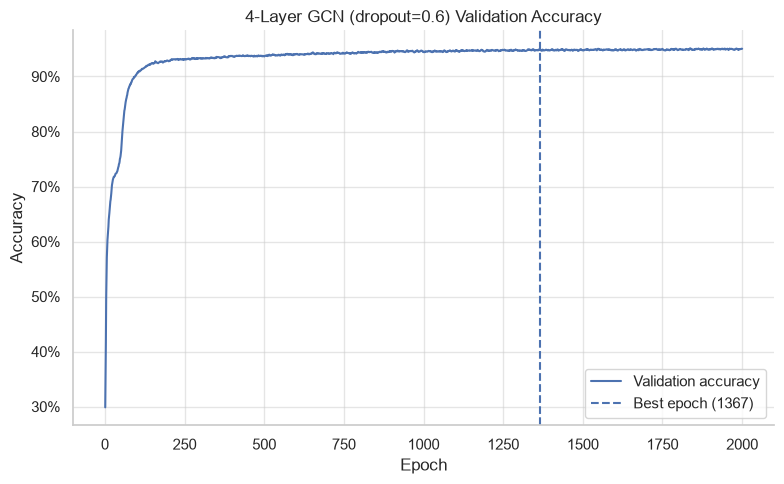

In [12]:
# plot 4-layer GCN (dropout=0.6) validation accuracy

gcn4_drop_06_accuracy_fig, gcn4_drop_06_accuracy_ax = plt.subplots(
    figsize=(8, 5)
)

gcn4_drop_06_accuracy_ax.plot(
    gcn4_drop_06_epochs,
    gcn4_drop_06_history["val_accuracy"],
    label="Validation accuracy",
)
gcn4_drop_06_accuracy_ax.axvline(
    gcn4_drop_06_best_epoch,
    linestyle="--",
    label=f"Best epoch ({gcn4_drop_06_best_epoch})",
)

gcn4_drop_06_accuracy_ax.set(
    xlabel="Epoch",
    ylabel="Accuracy",
    title="4-Layer GCN (dropout=0.6) Validation Accuracy",
)
gcn4_drop_06_accuracy_ax.yaxis.set_major_formatter(
    PercentFormatter(1.0)
)
gcn4_drop_06_accuracy_ax.legend()

sns.despine(ax=gcn4_drop_06_accuracy_ax)
gcn4_drop_06_accuracy_fig.tight_layout()

plt.show()

In [14]:
# save the 4-layer gcn (dropout=0.6) validation acc plot
gcn4_drop_06_accuracy_fig.savefig(
    FIGURES_DIR / "gcn_4layer_dropout06_training_validation_acc_2000e.png",
    dpi=200,
    bbox_inches="tight"
)

Reset for the next run

In [ ]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)